In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

In [4]:
from datasets import load_dataset

In [6]:
#load hugging face data
ds = load_dataset(
    "sentence-transformers/quora-duplicates",
    "pair-class"
)
df = ds['train'].to_pandas()# Convert train split to dataframe

In [7]:
df.head()

,sentence1,sentence2,label
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [8]:
df.shape

(404290, 3)

In [13]:

df.describe()


,label
count,404290.000000
mean,0.369198
std,0.482588
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [14]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 3 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   sentence1  404290 non-null  object
 1   sentence2  404290 non-null  object
 2   label      404290 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 9.3+ MB


In [16]:
df.isnull().sum()

sentence1    0
sentence2    0
label        0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

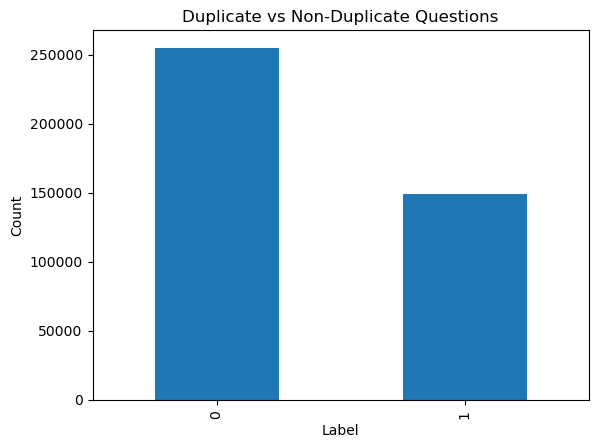

In [21]:
#Understand Target Distribution
df['label'].value_counts().plot(kind='bar')
plt.xlabel("Label")
plt.ylabel("Count")
plt.title("Duplicate vs Non-Duplicate Questions")
plt.show()

In [33]:
# Character length of sentence1
df['que1_length'] = df['sentence1'].apply(len)

# Character length of sentence2
df['que2_length'] = df['sentence2'].apply(len)
df[['que1_length', 'que2_length']].describe()

,que1_length,que2_length
count,404290.000000,404290.000000
mean,59.536716,60.108365
std,29.940641,33.863870
min,1.000000,0.000000
25%,39.000000,39.000000
50%,52.000000,51.000000
75%,72.000000,72.000000
max,623.000000,1169.000000


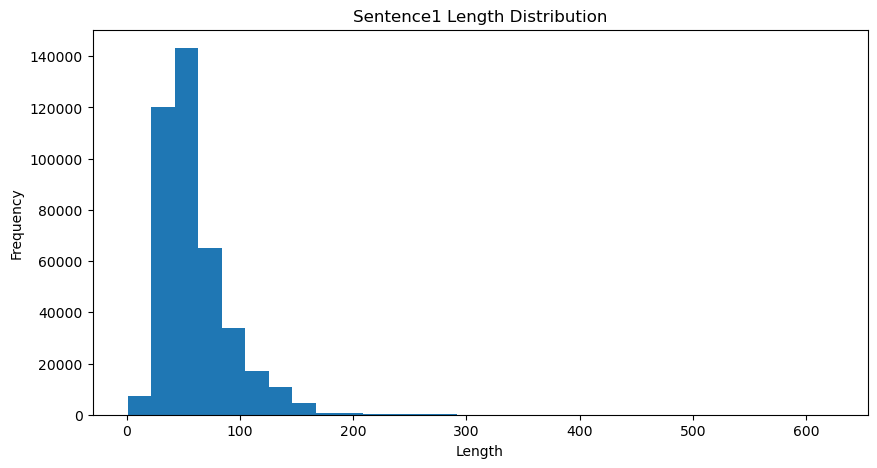

In [36]:
# Visualize sentence length
plt.figure(figsize=(10,5))
plt.hist(df['que1_length'],bins=30)
plt.title("Sentence1 Length Distribution")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()


In [39]:
# Count words in sentence1
df['que1_words'] = df['sentence1'].apply(lambda x: len(x.split())
)

# Count words in sentence2
df['que2_words'] = df['sentence2'].apply(lambda x: len(x.split())
)
print(df[['que1_words', 'que2_words']].describe())

          que1_words     que2_words
count  404290.000000  404290.000000
mean       10.942210      11.181986
std         5.428824       6.305254
min         1.000000       0.000000
25%         7.000000       7.000000
50%        10.000000      10.000000
75%        13.000000      13.000000
max       125.000000     237.000000


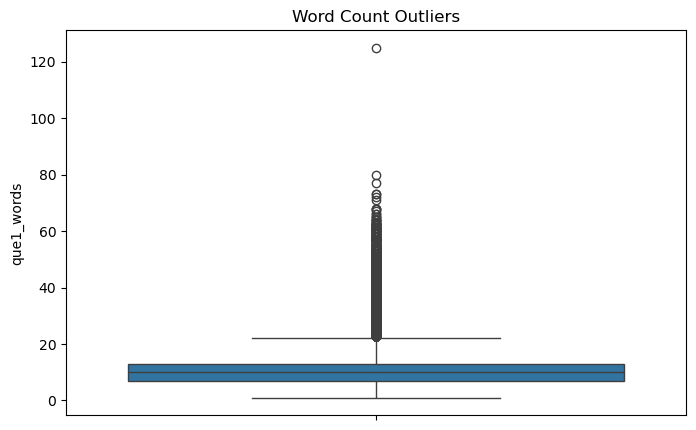

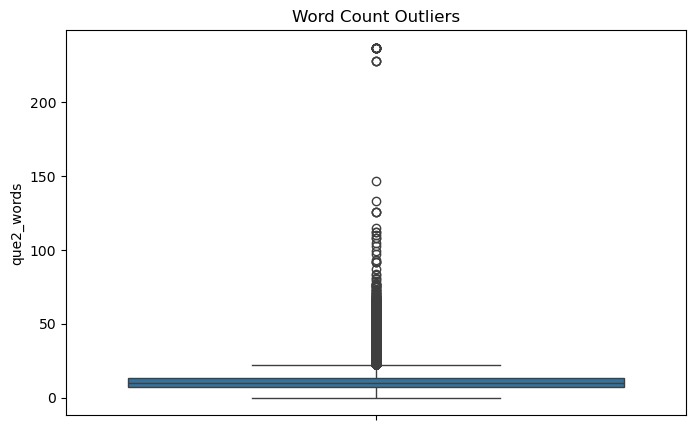

In [42]:
# BOXPLOT FOR OUTLIERS
plt.figure(figsize=(8,5))
sns.boxplot(df['que1_words'])
plt.title("Word Count Outliers")
plt.show()
plt.figure(figsize=(8,5))
sns.boxplot(df['que2_words'])
plt.title("Word Count Outliers")
plt.show()

In [45]:
# MOST COMMON WORDS

from collections import Counter

# Combine all sentence1 text
all_words = " ".join(
    df['sentence1'].astype(str)).split()

# Count frequency of words
common_words = Counter(all_words).most_common(20)

print(common_words)

[('the', 186114), ('What', 147489), ('is', 108147), ('a', 100298), ('I', 100126), ('How', 99943), ('to', 97855), ('in', 94407), ('of', 79312), ('do', 68336), ('are', 68235), ('and', 65622), ('for', 49920), ('can', 43217), ('you', 41929), ('Why', 35027), ('best', 33538), ('my', 31513), ('on', 29352), ('it', 28259)]


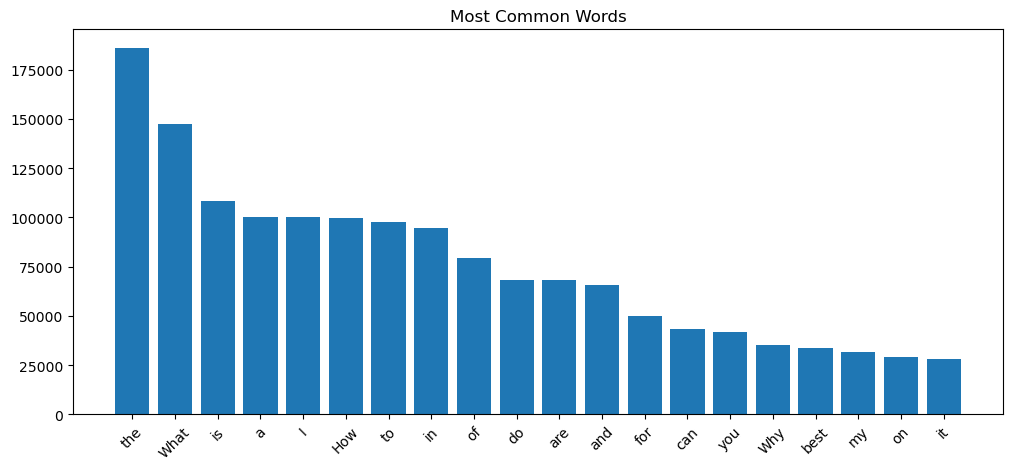

In [46]:

words = [i[0] for i in common_words]
counts = [i[1] for i in common_words]

plt.figure(figsize=(12,5))
plt.bar(words, counts)

plt.xticks(rotation=45)

plt.title("Most Common Words")
plt.show()

In [48]:
# Import regular expression library
import re

# Function for cleaning text
def clean_text(text):

    text = text.lower()

    # Remove special characters
    text = re.sub(
        r'[^a-zA-Z0-9 ]',
        '',
        text
    )
    return text


In [52]:
# Apply cleaning on sentence

df['clean_q1'] = df['sentence1'].apply(clean_text)
df['clean_q2'] = df['sentence2'].apply(clean_text)
#df[['sentence1', 'clean_q1']].head()
df[['sentence2', 'clean_q2']].head()




,sentence2,clean_q2
0,What is the step by step guide to invest in sh...,what is the step by step guide to invest in sh...
1,What would happen if the Indian government sto...,what would happen if the indian government sto...
2,How can Internet speed be increased by hacking...,how can internet speed be increased by hacking...
3,Find the remainder when [math]23^{24}[/math] i...,find the remainder when math2324math is divide...
4,Which fish would survive in salt water?,which fish would survive in salt water


In [55]:

# Filter duplicate questions
duplicate_questions = df[df['label'] == 1]
duplicate_questions[['sentence1', 'sentence2']].head()

,sentence1,sentence2
5,Astrology: I am a Capricorn Sun Cap moon and c...,"I'm a triple Capricorn (Sun, Moon and ascendan..."
7,How can I be a good geologist?,What should I do to be a great geologist?
11,How do I read and find my YouTube comments?,How can I see all my Youtube comments?
12,What can make Physics easy to learn?,How can you make physics easy to learn?
13,What was your first sexual experience like?,What was your first sexual experience?


In [54]:

# Filter non-duplicate questions
non_duplicate = df[df['label'] == 0]
non_duplicate[['sentence1', 'sentence2']].head()

,sentence1,sentence2
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?


# Baseline

Accuracy Score: 0.7416087461970368
F1 Score: 0.590614284314686
              precision    recall  f1-score   support

           0       0.75      0.88      0.81     51005
           1       0.71      0.50      0.59     29853

    accuracy                           0.74     80858
   macro avg       0.73      0.69      0.70     80858
weighted avg       0.74      0.74      0.73     80858



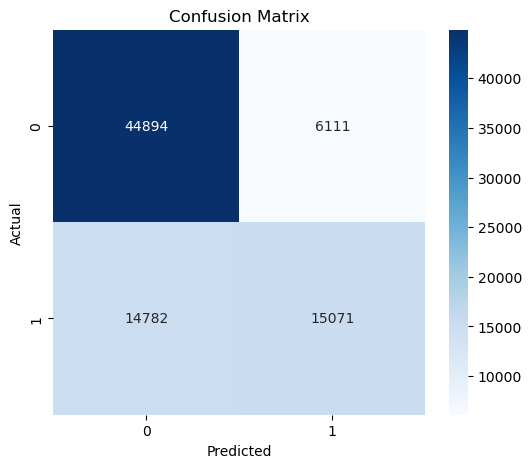

                                                 clean_q1  \
17222                        what type of guy should i be   
223267  i just started ketogenic diet im losing weight...   
367674                          how can i lose 4kg weight   
152597  why are there so many dumb questions asked on ...   
280836  what would happen to an astronaut who took the...   

                                                 clean_q2  label  Predicted  
17222         what type of guy should i find as a husband      0          0  
223267  i am trying to reach ketosis to lose weight wi...      0          0  
367674                          how do i reduce my weight      1          1  
152597   why do people ask such stupid questions on quora      1          1  
280836  what would really happen to an astronaut who t...      1          1  


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

# Convert text into TF-IDF vectors
q1_tfidf = tfidf.fit_transform(df['clean_q1'])
q2_tfidf = tfidf.transform(df['clean_q2'])

# Combine both question vectors
X = sp.hstack([q1_tfidf, q2_tfidf])

y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

results = df.iloc[y_test.index].copy()

results['Predicted'] = y_pred

print(
    results[['clean_q1','clean_q2','label','Predicted']].head())